# RetainIQ 04 - Prioritise and Act
RECOMMENDATION. Only active customers are ranked, using out-of-fold probabilities.

In [1]:
import sys, json, pandas as pd
sys.path.insert(0, '../src')
from IPython.display import Image, display, Markdown
pd.set_option('display.width', 200)

In [2]:
import prioritise, pilot_power
prioritise.main()
pilot_power.main()

[PASS] ranked list contains only active customers
[PASS] ranked list size == active customers
[PASS] probabilities are out-of-fold
[PASS] all tiers populated
               customers  mean_prob  expected_churners  total_balance  balance_at_risk  annual_value_at_risk     net_value  positive_net  share_balance_at_risk
priority_tier                                                                                                                                                  
P1                   118   0.273690          32.295379      8192490.0     2.065880e+06          55013.784171  15308.270503            86               0.117389
P2                  1988   0.042111          83.715746    259412992.0     8.983422e+06         237514.656999  62988.794199          1029               0.510464
P3                  1988   0.317032         630.259982     12033953.0     3.715278e+06         134262.385145  70617.431087          1988               0.211113
P4                  4328   0.074653       

                       group  customers  baseline_pred_churn  n_per_arm_for_4pp  n_per_arm_for_20pct_relative  mde_with_available_n
0         P1+P2 (high value)       2106             0.055086                304                          6076              0.024475
1          P1+P3 (high risk)       2106             0.314604               2037                           803              0.055176
2  Top 40% risk (all values)       3369             0.247371               1721                          1107              0.040418
              n  mean_pred  mean_balance  p1_share  mass_market_share
arm                                                                  
control    1051   0.314494   8826.096099  0.054234           0.775452
treatment  1055   0.314713  10379.351659  0.057820           0.768720
achievable MDE: 0.0552
[PASS] arms balanced in size


In [3]:
pd.read_csv('../outputs/tier_summary.csv').round(2)

,priority_tier,customers,mean_prob,expected_churners,total_balance,balance_at_risk,annual_value_at_risk,net_value,positive_net,share_balance_at_risk
0,P1,118,0.27,32.30,8192490.0,2065880.14,55013.78,15308.27,86,0.12
1,P2,1988,0.04,83.72,259412992.0,8983422.07,237514.66,62988.79,1029,0.51
2,P3,1988,0.32,630.26,12033953.0,3715277.81,134262.39,70617.43,1988,0.21
3,P4,4328,0.07,323.10,40345885.0,2833962.39,106541.25,63924.75,4328,0.16


In [4]:
pd.read_csv('../outputs/ranked_customers.csv').head(20)

,customer_id,priority_rank,priority_tier,risk_tier,churn_probability,avg_monthly_balance,balance_at_risk,annual_value,annual_value_at_risk,intervention_cost,net_retention_value,priority_score,top_reasons,persona,customer_segment,num_products,complaint_count_last_year,last_transaction_days_ago,recommended_action
0,CUST109832,1,P2,Medium,0.085049,1142086.0,97132.856825,28752.150,2445.331148,40.0,1427.198689,1427.198689,2 complaint(s) last year + low NPS (0) + Priva...,Multi-Product Wealthy,Private Banking,4.0,2.0,23.0,"Nurture & deepen: cross-sell / loyalty, protec..."
1,CUST108142,2,P1,High,0.187762,532169.0,99921.235722,13454.225,2526.195227,150.0,1365.717136,1365.717136,only 3 products + 1 complaint(s) last year + s...,Multi-Product Wealthy,Private Banking,3.0,1.0,24.0,Save now: RM call within 5 days + bespoke offe...
2,CUST105665,3,P1,High,0.201954,449560.0,90790.514972,11389.000,2300.055999,150.0,1230.033600,1230.033600,low NPS (-19) + 1 complaint(s) last year + sho...,Multi-Product Wealthy,Private Banking,3.0,1.0,2.0,Save now: RM call within 5 days + bespoke offe...
3,CUST100486,4,P1,High,0.335638,225827.0,75796.141366,5845.675,1962.031151,150.0,1027.218690,1027.218690,only 4 products + 2 complaint(s) last year + l...,Multi-Product Wealthy,Private Banking,4.0,2.0,18.0,Save now: RM call within 5 days + bespoke offe...
4,CUST106605,5,P1,High,0.265651,265568.0,70548.446881,6789.200,1803.558846,150.0,932.135307,932.135307,2 complaint(s) last year + low digital engagem...,Multi-Product Wealthy,Private Banking,3.0,2.0,47.0,Save now: RM call within 5 days + bespoke offe...
5,CUST104839,6,P1,High,0.195014,304386.0,59359.547631,7859.650,1532.742204,150.0,769.645322,769.645322,only 5 products + low digital engagement (34/1...,Multi-Product Wealthy,Private Banking,5.0,0.0,21.0,Save now: RM call within 5 days + bespoke offe...
6,CUST109602,7,P2,Medium,0.096294,549522.0,52915.493009,13888.050,1337.331377,40.0,762.398826,762.398826,low digital engagement (29/100) + short tenure...,Multi-Product Wealthy,Private Banking,3.0,0.0,73.0,"Nurture & deepen: cross-sell / loyalty, protec..."
7,CUST107725,8,P1,High,0.210665,274405.0,57807.646839,7110.125,1497.857528,150.0,748.714517,748.714517,only 5 products + low NPS (-7) + short tenure ...,Multi-Product Wealthy,Private Banking,5.0,0.0,48.0,Save now: RM call within 5 days + bespoke offe...
8,CUST100795,9,P2,Medium,0.135098,352861.0,47670.798135,9071.525,1225.544441,40.0,695.326665,695.326665,only 5 products + low digital engagement (31/1...,Multi-Product Wealthy,Private Banking,5.0,1.0,60.0,"Nurture & deepen: cross-sell / loyalty, protec..."
9,CUST100473,10,P2,Low,0.063799,743085.0,47407.713391,18777.125,1197.952536,40.0,678.771522,678.771522,1 complaint(s) last year + only 4 products + s...,Multi-Product Wealthy,Private Banking,4.0,1.0,18.0,"Nurture & deepen: cross-sell / loyalty, protec..."


In [5]:
pd.read_csv('../outputs/prioritisation_sensitivity.csv').round(3)

,scenario,jaccard_top250,share_of_top250_changed,n_positive_net_value,total_net_value_top250,p1_jaccard_vs_base,p1_size
0,value horizon 1 year,0.623,0.232,6459.0,16992.493,NaN,NaN
1,value horizon 5 years,0.901,0.052,7809.0,123053.409,NaN,NaN
2,NIM halved (1.25%),0.706,0.172,6930.0,31312.152,NaN,NaN
3,NIM +50% (3.75%),0.887,0.060,7724.0,107757.602,NaN,NaN
4,fee per product 0,0.908,0.048,7274.0,65565.325,NaN,NaN
5,fee per product 100,0.946,0.028,7512.0,72537.406,NaN,NaN
6,save rate 10%,0.767,0.132,6867.0,29398.104,NaN,NaN
7,save rate 30%,0.923,0.040,7747.0,109446.974,NaN,NaN
8,flat contact cost 10,0.761,0.136,6181.0,80079.347,NaN,NaN
9,flat contact cost 50,0.761,0.136,1577.0,70079.347,NaN,NaN


In [6]:
pd.read_csv('../outputs/pilot_sizing.csv').round(4)

,group,customers,baseline_pred_churn,n_per_arm_for_4pp,n_per_arm_for_20pct_relative,mde_with_available_n
0,P1+P2 (high value),2106,0.0551,304,6076,0.0245
1,P1+P3 (high risk),2106,0.3146,2037,803,0.0552
2,Top 40% risk (all values),3369,0.2474,1721,1107,0.0404


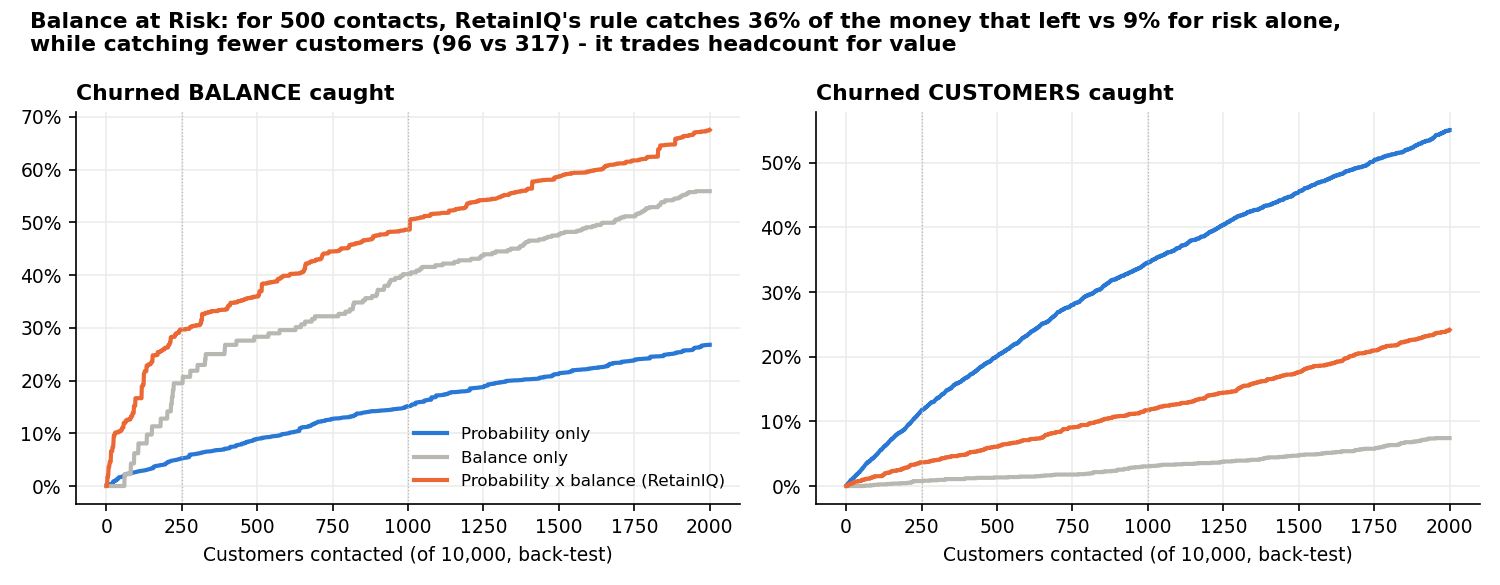

In [7]:
display(Image('../outputs/figures/17_budget_gain_curves.png'))

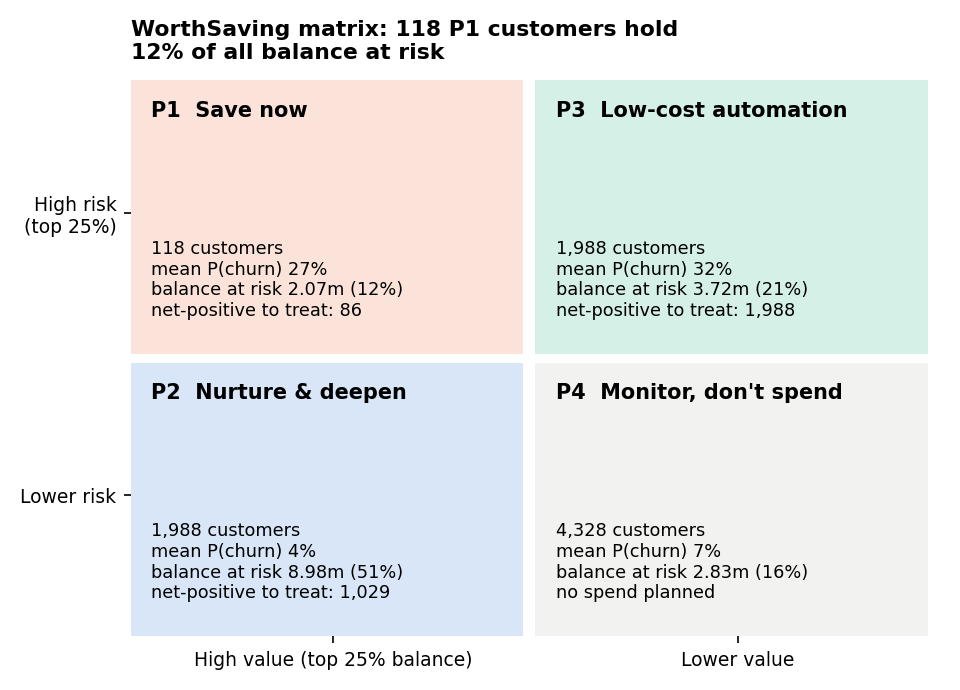

In [8]:
display(Image('../outputs/figures/18_worthsaving_matrix.png'))